In [1]:
# Cellule 1 : Simulation du Jumeau Numérique
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

# Paramètres du Jumeau (Serveur Virtuel)
np.random.seed(42)
time_points = pd.date_range(start=datetime.now(), periods=100, freq='min')

# Données "Réelles" (avec bruit)
real_temperature = 50 + np.sin(np.linspace(0, 10, 100)) * 5 + np.random.normal(0, 1, 100)
rpm = np.random.randint(800, 1200, 100)

# Modèle du Jumeau (Physique simulée : Temp dépend du RPM)
twin_temperature = (rpm / 20) + np.random.normal(0, 0.5, 100)

df_twin = pd.DataFrame({
    'time': time_points,
    'real_temp': real_temperature,
    'twin_temp': twin_temperature,
    'rpm': rpm
})

df_twin.head()

,time,real_temp,twin_temp,rpm
0,2026-04-30 12:06:01.579813,50.496714,46.854356,936
1,2026-04-30 12:07:01.579813,50.365928,55.902882,1117
2,2026-04-30 12:08:01.579813,51.650933,48.660333,964
3,2026-04-30 12:09:01.579813,53.015099,51.086639,1024
4,2026-04-30 12:10:01.579813,51.731530,55.626524,1106


In [2]:
# Cellule 2 : Détection de Dérive (Anomaly Detection)
# Le Jumeau détecte si la réalité s'écarte de la simulation
df_twin['drift'] = df_twin['real_temp'] - df_twin['twin_temp']
threshold = 3.0 # Degrés d'écart max

df_twin['anomaly'] = df_twin['drift'].apply(lambda x: 'Normal' if abs(x) < threshold else 'Dérive Critique')

print(f"Pourcentage de temps où le système est synchronisé : {100 - len(df_twin[df_twin['anomaly'] == 'Dérive Critique'])}")

Pourcentage de temps où le système est synchronisé : 32


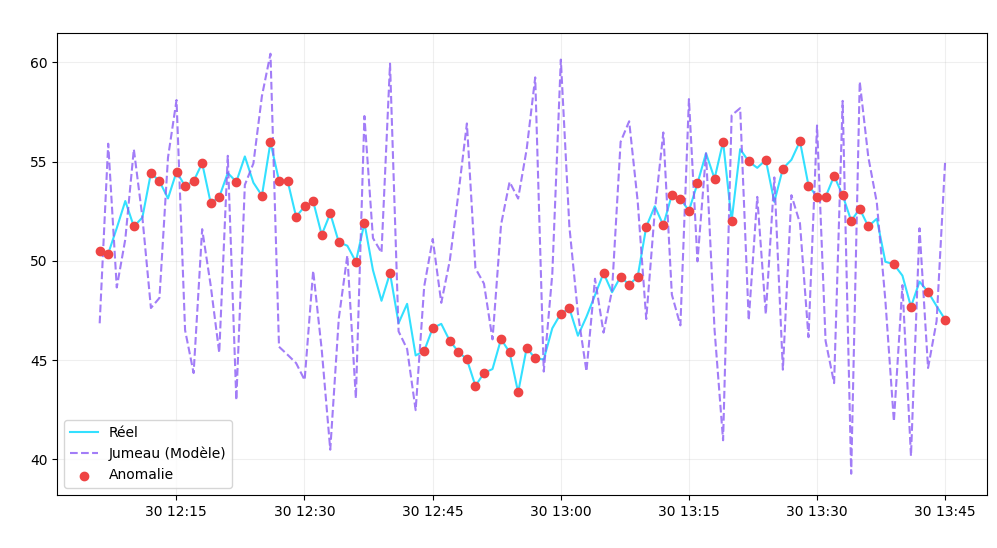

: 

In [ ]:
# Cellule 3 : Visualisation du Jumeau
plt.figure(figsize=(12, 6))
plt.plot(df_twin['time'], df_twin['real_temp'], label='Réel', color='#00d9ff', alpha=0.8)
plt.plot(df_twin['time'], df_twin['twin_temp'], label='Jumeau (Modèle)', color='#8b5cf6', linestyle='--', alpha=0.8)

# Mettre en évidence les anomalies
anomalies = df_twin[df_twin['anomaly'] == 'Dérive Critique']
if not anomalies.empty:
    plt.scatter(anomalies['time'], anomalies['real_temp'], color='#ef4444', label='Anomalie', zorder=5)

plt.title('Jumeau Numérique : Synchronisation Réel vs Virtuel', color='white')
plt.xlabel('Temps', color='white')
plt.ylabel('Température (°C)', color='white')
plt.legend()
plt.grid(True, alpha=0.2)
plt.show()